# EDA · Auditor de Preço Justo

Análise exploratória dos dados do Bondora já carregados no banco. Gera as figuras dos slides em `docs/figuras/`.

**Como rodar:** com o banco no ar e o `.env` preenchido (`DATABASE_URL`), execute as células em ordem.
No VS Code, escolha o kernel do ambiente do projeto (ele pede para instalar o `ipykernel` na primeira vez).
Precisa de `matplotlib` e `seaborn` (`pip install -r requirements-dev.txt`).

| Figura | Pergunta |
| --- | --- |
| 1 | Qual a proporção de contratos inadimplentes por ano e país? |
| 2 | Como o juro mudou ao longo do tempo e como ele se relaciona com o rating do Bondora? |
| 3 | Qual a renda dos clientes em cada país? |
| 4 | O juro cobrado acompanha o default que realmente aconteceu? |
| 5 | A codificação do gênero é confiável ao longo dos anos? (governança e ética) |
| 6 | Como se descobriu e se corrigiu a renda em coroas estonianas (2009–2010)? |
| 7 | O que a carteira devolveu, em euros? (base do ROI) |
| 8 | Há diferença de juro entre gêneros e idades, com intervalo de confiança? *(depende do `equidade.json` do Samuel)* |
| 9 | Quanto do preço está fora da margem, e o que isso vale em euros? *(depende do `carteira_auditoria.csv` do Samuel)* |
| 10 | A conversão da taxa do BC (efetiva para nominal) bate com a série mensal oficial? *(depende do `bcdata.sgs.25464.csv`)* |

In [1]:
import json
import os
import sys
from pathlib import Path
sys.path.append('../..')

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv

from src.dados import validacao as v
from src.dados.moeda import DATA_EURO, TAXA_EEK_POR_EUR

RAIZ = Path('../..').resolve()
load_dotenv(RAIZ / '.env', override=True)   # o .env do projeto vale mais que variáveis antigas do kernel
FIGURAS = RAIZ / 'docs' / 'figuras'
FIGURAS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
PAISES = ['EE', 'ES', 'FI']
NOMES = {'EE': 'Estônia', 'ES': 'Espanha', 'FI': 'Finlândia'}
CORES = {'EE': '#1f77b4', 'ES': '#d62728', 'FI': '#2ca02c'}


def salvar(fig, nome):
    caminho = FIGURAS / f'{nome}.png'
    fig.savefig(caminho, dpi=150, bbox_inches='tight')
    print('gravado:', caminho.relative_to(RAIZ))


def rodape(fig, texto, y=-0.03):
    fig.text(0.01, y, texto, fontsize=9, color='dimgray', ha='left', va='top', wrap=True)


def br(x, casas=2, sinal=False):
    # número no padrão brasileiro: ponto nos milhares e vírgula nos decimais
    t = f'{x:+,.{casas}f}' if sinal else f'{x:,.{casas}f}'
    return t.replace(',', '§').replace('.', ',').replace('§', '.')

## 1. Dados

Lê as tabelas do banco com a mesma função da validação. A Eslováquia (296 contratos, quase todos de 2014) fica fora dos gráficos.

In [2]:
print('Conectando em:', os.environ['DATABASE_URL'].split('@')[-1])   # servidor, porta e banco (sem a senha)
tabelas = v.ler_tabelas(v.conectar_ou_sair(os.environ['DATABASE_URL']))
emp, cli, vw = tabelas['emprestimo'], tabelas['cliente'], tabelas['vw_base_modelagem']

base = (emp[['loan_id', 'data_emprestimo', 'juro_aa', 'rating', 'valor_concedido']]
        .merge(cli[['loan_id', 'pais', 'genero', 'renda_total']], on='loan_id'))
base['ano'] = base['data_emprestimo'].dt.year
base = base[base['pais'].isin(PAISES)]

print(f'{len(base):,} contratos (sem a Eslováquia)'.replace(',', '.'))
print('Renda e passivos da Estônia até 2010 já vêm convertidos de coroas para euros (src/dados/moeda.py).')
print(f'Base de modelagem (vw_base_modelagem): {len(vw):,} contratos'.replace(',', '.'))
print('\nContratos por ano de concessão e país:')
base.groupby(['ano', 'pais']).size().unstack(fill_value=0)

Conectando em: localhost:5433/auditor_db
178.939 contratos (sem a Eslováquia)
Renda e passivos da Estônia até 2010 já vêm convertidos de coroas para euros (src/dados/moeda.py).
Base de modelagem (vw_base_modelagem): 29.916 contratos

Contratos por ano de concessão e país:


pais,EE,ES,FI
ano,,,
2009,665,0,0
2010,1157,0,0
2011,451,0,0
2012,457,0,0
2013,2286,61,165
2014,4145,1609,1408
2015,3432,2187,2424
2016,6023,2642,1849
2017,11109,4174,2650


## Figura 1 · Inadimplência por ano e país

Só entram os contratos da **base de modelagem** (encerrados, concedidos de 2009 a 2016): a partir de 2017 os contratos ainda não têm desfecho suficiente.
Pontos vazados têm menos de 200 contratos.

gravado: docs\figuras\01_inadimplencia_por_ano_pais.png


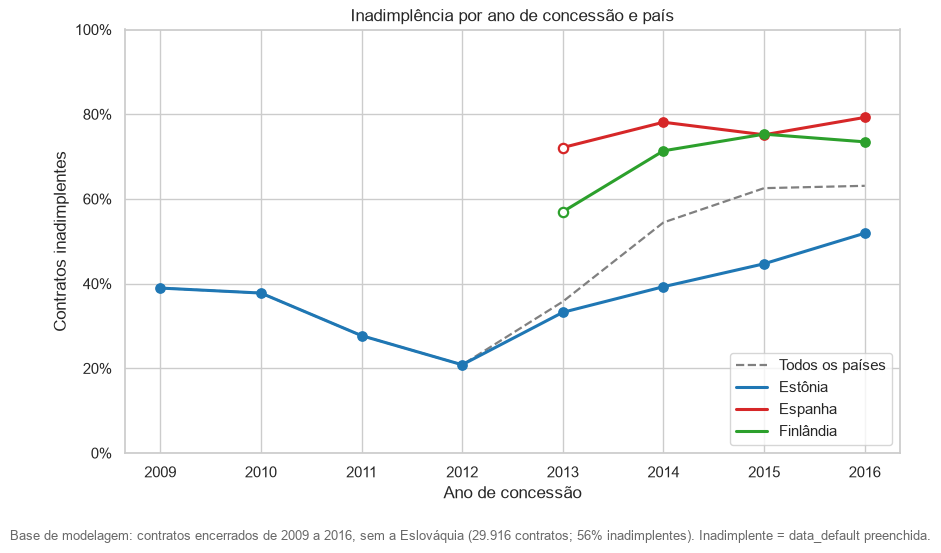

Inadimplência (%) por ano e país:


pais,EE,ES,FI
ano,,,
2009,39.0,NaN,NaN
2010,38.0,NaN,NaN
2011,28.0,NaN,NaN
2012,21.0,NaN,NaN
2013,33.0,72.0,57.0
2014,39.0,78.0,71.0
2015,45.0,75.0,75.0
2016,52.0,79.0,73.0


In [3]:
d = (vw.groupby(['ano', 'pais'])
       .agg(n=('inadimplente', 'size'), taxa=('inadimplente', 'mean')).reset_index())
d['taxa'] *= 100
geral = vw.groupby('ano')['inadimplente'].mean() * 100

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(geral.index, geral.values, color='gray', ls='--', lw=1.6, label='Todos os países')
for p in PAISES:
    g = d[d['pais'] == p]
    ax.plot(g['ano'], g['taxa'], color=CORES[p], lw=2.2, label=NOMES[p])
    pouco = g['n'] < 200
    ax.scatter(g.loc[~pouco, 'ano'], g.loc[~pouco, 'taxa'], color=CORES[p], s=45, zorder=3)
    ax.scatter(g.loc[pouco, 'ano'], g.loc[pouco, 'taxa'], facecolors='white',
               edgecolors=CORES[p], s=45, linewidths=1.6, zorder=3)
ax.set(ylim=(0, 100), xlabel='Ano de concessão', ylabel='Contratos inadimplentes',
       title='Inadimplência por ano de concessão e país')
ax.set_xticks(range(2009, 2017))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.legend(loc='lower right', frameon=True)
n_vw = f'{len(vw):,}'.replace(',', '.')
rodape(fig, f'Base de modelagem: contratos encerrados de 2009 a 2016, sem a Eslováquia '
            f'({n_vw} contratos; {vw["inadimplente"].mean()*100:.0f}% inadimplentes). '
            'Inadimplente = data_default preenchida.')
salvar(fig, '01_inadimplencia_por_ano_pais')
plt.show()

print('Inadimplência (%) por ano e país:')
display(d.pivot(index='ano', columns='pais', values='taxa').round(0))

## Figura 2 · Juro por época e por rating

À esquerda, o juro mediano por ano e país (todos os contratos, 2009–2021). À direita, o juro mediano por **rating do Bondora** e ano.
Se o preço seguisse o risco, as linhas do rating estariam bem separadas em todos os anos.
Juros acima de 100% (Espanha e Finlândia, 2016–2018) são legítimos, não erro de dado.

gravado: docs\figuras\02_juros_por_epoca_e_rating.png


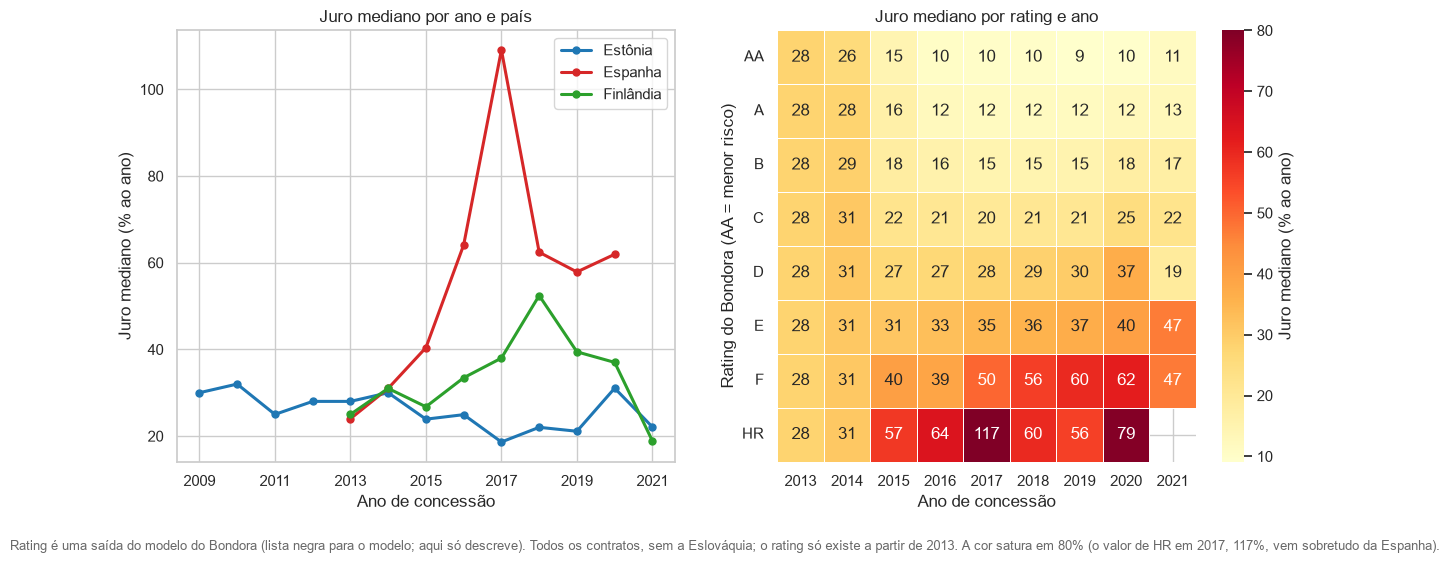

In [4]:
mediana = base.groupby(['ano', 'pais'])['juro_aa'].median().unstack()

ordem = ['AA', 'A', 'B', 'C', 'D', 'E', 'F', 'HR']
r = base[base['rating'].isin(ordem) & base['ano'].between(2013, 2021)]
por_rating = r.groupby(['rating', 'ano'])['juro_aa'].median().unstack().reindex(ordem)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.6), gridspec_kw={'width_ratios': [1, 1.05]})
for p in PAISES:
    ax1.plot(mediana.index, mediana[p], color=CORES[p], lw=2.2, marker='o', ms=5, label=NOMES[p])
ax1.set(xlabel='Ano de concessão', ylabel='Juro mediano (% ao ano)', title='Juro mediano por ano e país')
ax1.set_xticks(range(2009, 2022, 2))
ax1.legend(frameon=True)

sns.heatmap(por_rating, annot=True, fmt='.0f', cmap='YlOrRd', vmax=80, linewidths=0.5, ax=ax2,
            cbar_kws={'label': 'Juro mediano (% ao ano)'})
ax2.set(xlabel='Ano de concessão', ylabel='Rating do Bondora (AA = menor risco)',
        title='Juro mediano por rating e ano')
ax2.tick_params(axis='y', rotation=0)
rodape(fig, 'Rating é uma saída do modelo do Bondora (lista negra para o modelo; aqui só descreve). '
            'Todos os contratos, sem a Eslováquia; o rating só existe a partir de 2013. '
            'A cor satura em 80% (o valor de HR em 2017, 117%, vem sobretudo da Espanha).')
salvar(fig, '02_juros_por_epoca_e_rating')
plt.show()

## Figura 3 · Renda por país

Só contratos com renda maior que zero, de 2009 a 2021. A renda e os passivos da **Estônia até 2010 estavam em coroas**, e a carga os converte para euros (÷ 15,6466; `src/dados/moeda.py`),
então 2009 e 2010 já entram no gráfico em euros. A figura 6 mostra a evidência e o efeito da correção.

Estônia · renda mediana (em euros) e razão renda/valor concedido (mediana), por ano:


,n,renda_mediana,renda_sobre_valor
ano,,,
2009,665,703.0,3.9
2010,1123,703.0,3.1
2011,442,800.0,1.0
2012,440,807.0,0.7
2013,2284,796.5,0.4


gravado: docs\figuras\03_renda_por_pais.png


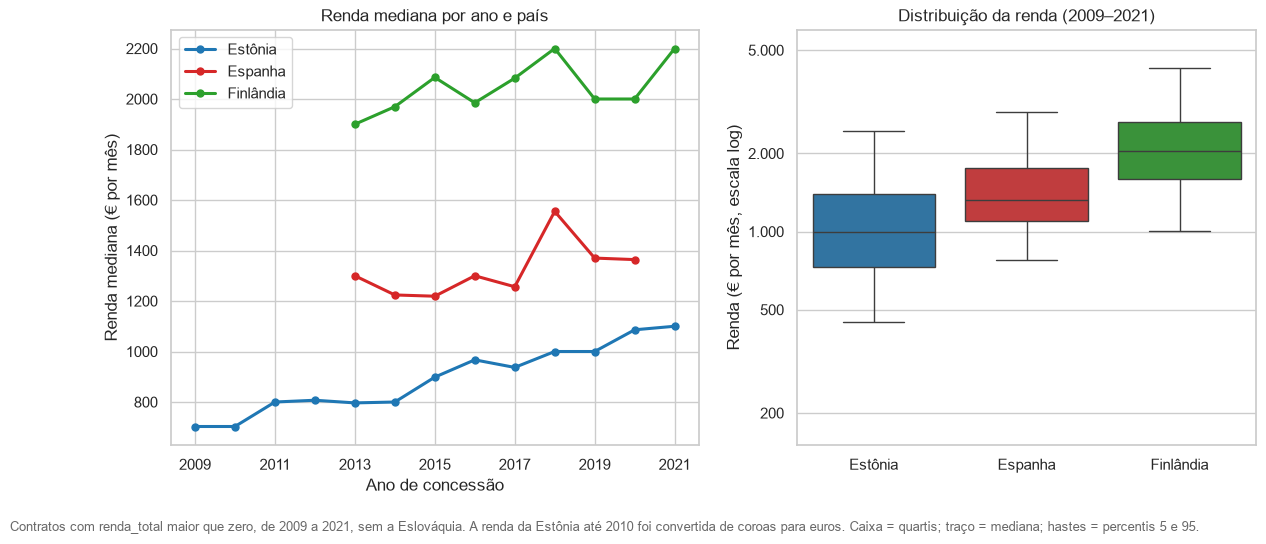

In [5]:
rend = base[base['renda_total'] > 0]
ee = rend[rend['pais'] == 'EE']
print('Estônia · renda mediana (em euros) e razão renda/valor concedido (mediana), por ano:')
display(ee[ee['ano'] <= 2013].groupby('ano').agg(
    n=('renda_total', 'size'), renda_mediana=('renda_total', 'median'),
    renda_sobre_valor=('renda_total', lambda s: (s / ee.loc[s.index, 'valor_concedido']).median())).round(1))

mediana_renda = rend.groupby(['ano', 'pais'])['renda_total'].median().unstack()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={'width_ratios': [1.15, 1]})
for p in PAISES:
    ax1.plot(mediana_renda.index, mediana_renda[p], color=CORES[p], lw=2.2, marker='o', ms=5, label=NOMES[p])
ax1.set(xlabel='Ano de concessão', ylabel='Renda mediana (€ por mês)', title='Renda mediana por ano e país')
ax1.set_xticks(range(2009, 2022, 2))
ax1.legend(frameon=True)

sns.boxplot(data=rend, x='pais', y='renda_total', order=PAISES, hue='pais', palette=CORES,
            legend=False, showfliers=False, whis=(5, 95), ax=ax2)
ax2.set_yscale('log')
ax2.set_ylim(150, 6000)
ax2.set_yticks([200, 500, 1000, 2000, 5000])
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.')))
ax2.minorticks_off()
ax2.set_xticks(range(3))
ax2.set_xticklabels([NOMES[p] for p in PAISES])
ax2.set(xlabel='', ylabel='Renda (€ por mês, escala log)', title='Distribuição da renda (2009–2021)')
rodape(fig, 'Contratos com renda_total maior que zero, de 2009 a 2021, sem a Eslováquia. A renda da Estônia até 2010 foi convertida de coroas '
            'para euros. Caixa = quartis; traço = mediana; hastes = percentis 5 e 95.')
salvar(fig, '03_renda_por_pais')
plt.show()

## Figura 4 · O juro cobrado acompanha o default realizado?

Dentro de cada país, os contratos da base de modelagem são divididos em cinco grupos pelo juro cobrado (Q1 = os 20% mais baratos).
O rótulo embaixo é o juro mediano do grupo. É uma leitura descritiva: o risco depende de muitas coisas além do juro.

gravado: docs\figuras\04_juro_cobrado_x_inadimplencia.png


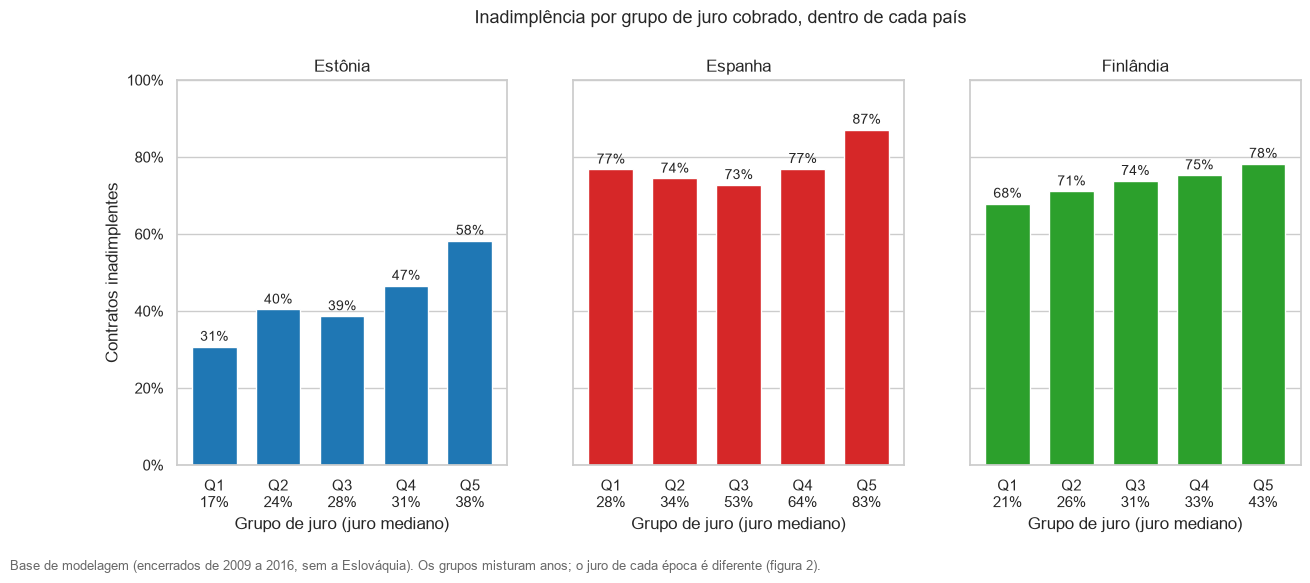

pais,EE,ES,FI
quintil,,,
1,31.0,77.0,68.0
2,40.0,74.0,71.0
3,39.0,73.0,74.0
4,47.0,77.0,75.0
5,58.0,87.0,78.0


In [6]:
q = vw.merge(emp[['loan_id', 'juro_aa']], on='loan_id')
q = q[q['pais'].isin(PAISES)].copy()
q['quintil'] = q.groupby('pais')['juro_aa'].transform(
    lambda s: pd.qcut(s, 5, labels=False, duplicates='drop')) + 1
res = (q.groupby(['pais', 'quintil'])
         .agg(default=('inadimplente', 'mean'), juro=('juro_aa', 'median'), n=('juro_aa', 'size'))
         .reset_index())

fig, axes = plt.subplots(1, 3, figsize=(14.5, 5), sharey=True)
for ax, p in zip(axes, PAISES):
    g = res[res['pais'] == p]
    ax.bar(g['quintil'], g['default'] * 100, color=CORES[p], width=0.7)
    for x, y in zip(g['quintil'], g['default'] * 100):
        ax.text(x, y + 1.5, f'{y:.0f}%', ha='center', fontsize=10)
    ax.set_xticks(g['quintil'])
    ax.set_xticklabels([f'Q{int(k)}\n{j:.0f}%' for k, j in zip(g['quintil'], g['juro'])])
    ax.set(title=NOMES[p], xlabel='Grupo de juro (juro mediano)', ylim=(0, 100))
    ax.grid(axis='x', visible=False)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
axes[0].set_ylabel('Contratos inadimplentes')
fig.suptitle('Inadimplência por grupo de juro cobrado, dentro de cada país', y=1.02, fontsize=13)
rodape(fig, 'Base de modelagem (encerrados de 2009 a 2016, sem a Eslováquia). '
            'Os grupos misturam anos; o juro de cada época é diferente (figura 2).', y=-0.08)
salvar(fig, '04_juro_cobrado_x_inadimplencia')
plt.show()

display(res.pivot(index='quintil', columns='pais', values='default').mul(100).round(0))

## Figura 5 · Gênero: um achado de governança

Proporção de mulheres entre os contratos com gênero informado (0 ou 1). Uma queda abrupta que depois volta ao nível anterior indica
**problema de codificação**, não mudança da clientela: 5.633 clientes aparecem com os dois gêneros em contratos diferentes, e a idade deles é coerente,
ou seja, é a mesma pessoa. O dicionário do Bondora não confirma a causa. Gênero fica fora do treino e do teste do modelo.

gravado: docs\figuras\05_genero_codificacao_por_ano.png


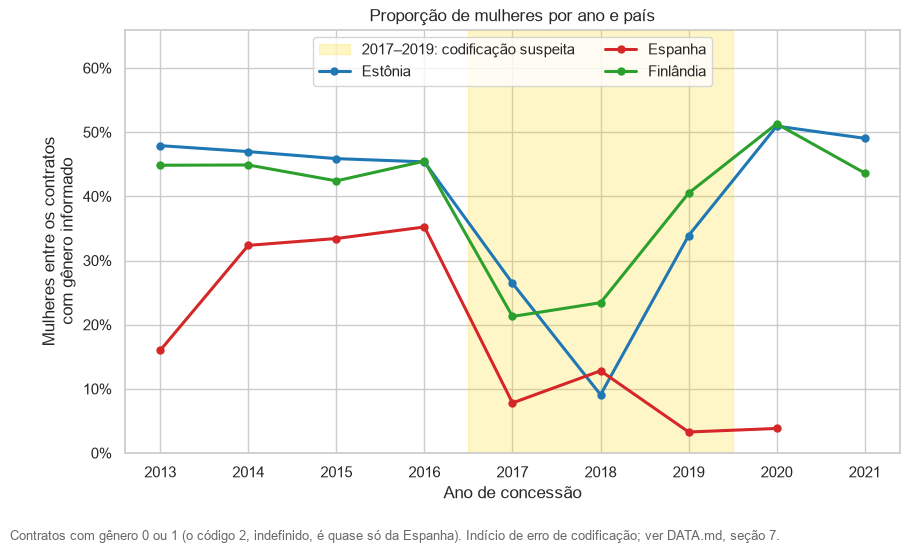

pais,EE,ES,FI
ano,,,
2013,48.0,16.0,45.0
2014,47.0,32.0,45.0
2015,46.0,33.0,42.0
2016,45.0,35.0,45.0
2017,26.0,8.0,21.0
2018,9.0,13.0,23.0
2019,34.0,3.0,41.0
2020,51.0,4.0,51.0
2021,49.0,NaN,44.0


In [7]:
gen = base[base['genero'].isin([0, 1]) & base['ano'].between(2013, 2021)]
mulheres = gen.groupby(['ano', 'pais'])['genero'].mean().unstack() * 100

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.axvspan(2016.5, 2019.5, color='gold', alpha=0.22, label='2017–2019: codificação suspeita')
for p in PAISES:
    ax.plot(mulheres.index, mulheres[p], color=CORES[p], lw=2.2, marker='o', ms=5, label=NOMES[p])
ax.set(ylim=(0, 66), xlabel='Ano de concessão', ylabel='Mulheres entre os contratos\ncom gênero informado',
       title='Proporção de mulheres por ano e país')
ax.set_xticks(range(2013, 2022))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
ax.legend(loc='upper center', ncol=2, frameon=True)
rodape(fig, 'Contratos com gênero 0 ou 1 (o código 2, indefinido, é quase só da Espanha). '
            'Indício de erro de codificação; ver DATA.md, seção 7.')
salvar(fig, '05_genero_codificacao_por_ano')
plt.show()

display(mulheres.round(0))

## Figura 6 · A correção da moeda (coroas estonianas)

Até 31/12/2010 a Estônia usava a coroa. A renda e os passivos dos clientes ficaram em coroas no arquivo do Bondora, enquanto os valores dos empréstimos já vinham em euros. Duas provas:

1. **O salto em 01/2011** (à esquerda): sem a correção, a renda mediana da Estônia cai de 12.000 (dez/2010) para 860 (jan/2011). A linha tracejada reconstrói o "como veio no arquivo"
   (multiplica por 15,6466 os contratos anteriores a 2011); a linha contínua é o dado já corrigido, sem salto.
2. **Números redondos** (à direita): o valor pedido multiplicado por 15,6466 dá um múltiplo de 50 coroas em 100% dos contratos até 2010 e em 0% depois.
   Ou seja, o Bondora converteu os valores dos empréstimos para euros, mas não a renda nem os passivos.

gravado: docs\figuras\06_correcao_da_moeda.png


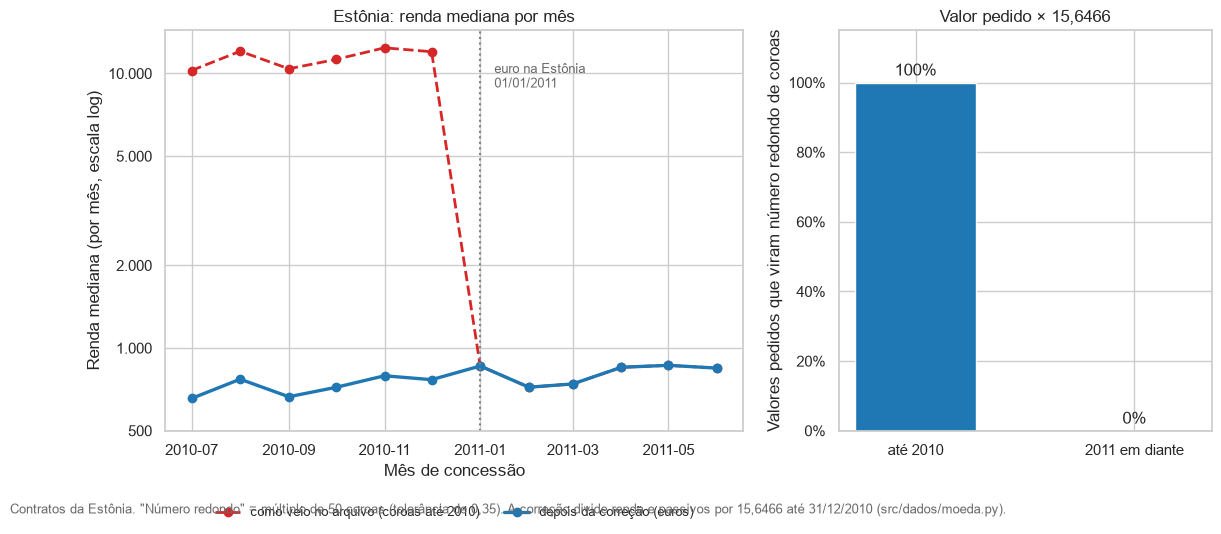

Estônia · renda mediana por mês (set/2010 a abr/2011):


,no arquivo,corrigida
mes,,
2010-09-01,10400.0,665.0
2010-10-01,11250.0,719.0
2010-11-01,12400.0,792.0
2010-12-01,12000.0,767.0
2011-01-01,860.0,860.0
2011-02-01,720.0,720.0
2011-03-01,740.0,740.0
2011-04-01,851.0,851.0


In [8]:
est = base[(base['pais'] == 'EE') & (base['renda_total'] > 0)].copy()
est['mes'] = est['data_emprestimo'].dt.to_period('M').dt.to_timestamp()
est['renda_no_arquivo'] = np.where(est['data_emprestimo'] < DATA_EURO,
                                   est['renda_total'] * TAXA_EEK_POR_EUR, est['renda_total'])
janela = est[(est['mes'] >= '2010-07-01') & (est['mes'] <= '2011-06-01')]
corrigida = janela.groupby('mes')['renda_total'].median()
no_arquivo = janela.groupby('mes')['renda_no_arquivo'].median()


def redondo_em_coroas(s):
    k = s.dropna() * TAXA_EEK_POR_EUR
    return ((k - (k / 50).round() * 50).abs() < 0.35).mean() * 100


pedidos = emp.merge(cli[['loan_id', 'pais']], on='loan_id')
pedidos = pedidos[pedidos['pais'] == 'EE']
redondo_ate_2010 = redondo_em_coroas(pedidos.loc[pedidos['data_emprestimo'] < DATA_EURO, 'valor_solicitado'])
redondo_depois = redondo_em_coroas(pedidos.loc[pedidos['data_emprestimo'] >= DATA_EURO, 'valor_solicitado'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={'width_ratios': [1.55, 1]})
ax1.plot(no_arquivo.index, no_arquivo.values, color='#d62728', ls='--', marker='o', lw=2, label='como veio no arquivo (coroas até 2010)')
ax1.plot(corrigida.index, corrigida.values, color='#1f77b4', marker='o', lw=2.4, label='depois da correção (euros)')
ax1.axvline(pd.Timestamp('2011-01-01'), color='gray', ls=':')
ax1.text(pd.Timestamp('2011-01-10'), 11000, 'euro na Estônia\n01/01/2011', fontsize=9, color='dimgray', va='top')
ax1.set_yscale('log')
ax1.set_yticks([500, 1000, 2000, 5000, 10000])
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.')))
ax1.minorticks_off()
ax1.set(xlabel='Mês de concessão', ylabel='Renda mediana (por mês, escala log)', title='Estônia: renda mediana por mês')
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False, fontsize=9)

barras = ax2.bar(['até 2010', '2011 em diante'], [redondo_ate_2010, redondo_depois], color=['#1f77b4', '#9ecae1'], width=0.55)
for b, val in zip(barras, [redondo_ate_2010, redondo_depois]):
    ax2.text(b.get_x() + b.get_width() / 2, val + 2, f'{val:.0f}%', ha='center', fontsize=12)
ax2.set(ylim=(0, 115), ylabel='Valores pedidos que viram número redondo de coroas', title='Valor pedido × 15,6466')
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
rodape(fig, 'Contratos da Estônia. "Número redondo" = múltiplo de 50 coroas (tolerância de 0,35). '
            'A correção divide renda e passivos por 15,6466 até 31/12/2010 (src/dados/moeda.py).')
salvar(fig, '06_correcao_da_moeda')
plt.show()

print('Estônia · renda mediana por mês (set/2010 a abr/2011):')
display(pd.DataFrame({'no arquivo': no_arquivo, 'corrigida': corrigida}).loc['2010-09-01':'2011-04-01'].round(0))

## Figura 7 · O que a carteira devolveu (retorno realizado, em euros)

Usa a view `vw_retorno_realizado`: contratos da base de modelagem (2009–2016, encerrados, sem a Eslováquia).
**Retorno = (principal e juros recebidos − valor concedido) ÷ valor concedido.** As recuperações **já estão dentro** dos pagamentos, e por isso não se soma de novo.
Limites: não desconta o tempo, e só entram contratos encerrados, então as safras mais novas (2015 e 2016) podem ainda ter recuperações a chegar.

gravado: docs\figuras\07_retorno_realizado_eur.png


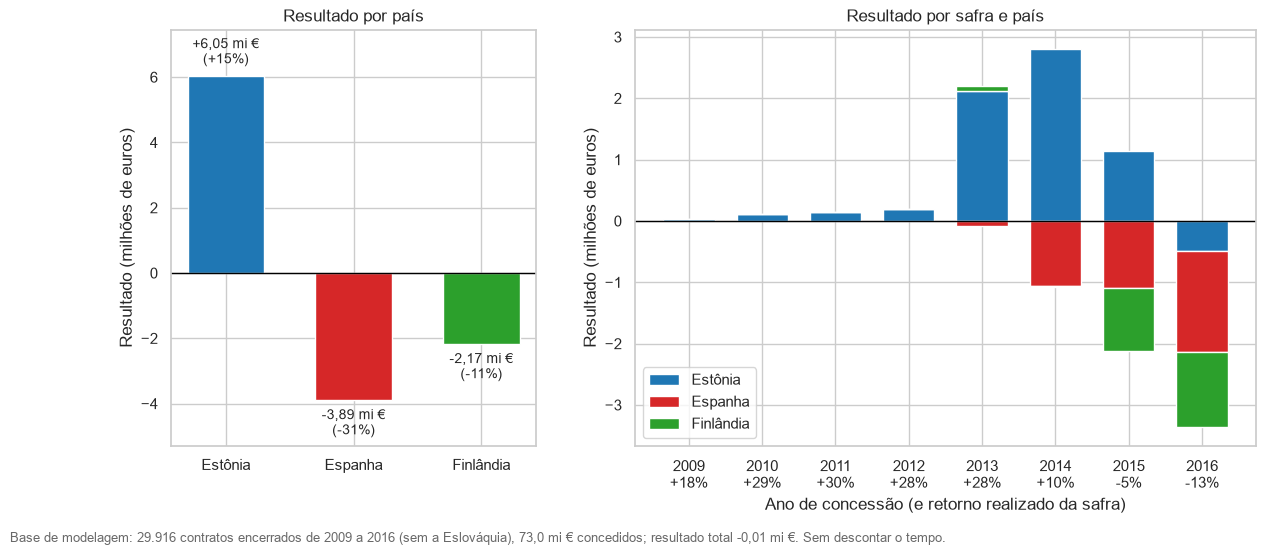

Carteira da base de modelagem:


,contratos,concedido_mi,recebido_mi,resultado_mi,retorno_%
carteira,29916,73.0,73.0,-0.01,-0.01


Reestruturados x demais:


,contratos,concedido_mi,resultado_mi,retorno_%
reestruturado,,,,
False,21975,49.16,-1.35,-2.74
True,7941,23.85,1.34,5.62


In [9]:
ret = tabelas['vw_retorno_realizado'].copy()
MI = 1e6


por_pais = ret.groupby('pais').agg(concedido=('valor_concedido', 'sum'), recebido=('recebido_total', 'sum'),
                                   resultado=('resultado_eur', 'sum')).reindex(PAISES)
por_pais['retorno_%'] = por_pais['resultado'] / por_pais['concedido'] * 100
por_ano = ret.groupby(['ano', 'pais'])['resultado_eur'].sum().unstack().reindex(columns=PAISES).fillna(0) / MI
g = ret.groupby('ano').agg(res=('resultado_eur', 'sum'), conc=('valor_concedido', 'sum'))
retorno_ano = g['res'] / g['conc'] * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={'width_ratios': [1, 1.7]})
val = por_pais['resultado'] / MI
barras = ax1.bar([NOMES[p] for p in PAISES], val.values, color=[CORES[p] for p in PAISES], width=0.6)
for b, p in zip(barras, PAISES):
    y = val[p]
    ax1.text(b.get_x() + b.get_width() / 2, y + (0.25 if y >= 0 else -0.25),
             f"{br(y, 2, True)} mi €\n({br(por_pais.loc[p, 'retorno_%'], 0, True)}%)", ha='center', va='bottom' if y >= 0 else 'top', fontsize=10)
ax1.axhline(0, color='black', lw=1)
ax1.set(ylim=(val.min() - 1.4, val.max() + 1.4), ylabel='Resultado (milhões de euros)', title='Resultado por país')

base_pos = np.zeros(len(por_ano)); base_neg = np.zeros(len(por_ano))
for p in PAISES:
    v_ = por_ano[p].values
    fundo = np.where(v_ >= 0, base_pos, base_neg)
    ax2.bar(por_ano.index, v_, bottom=fundo, color=CORES[p], width=0.7, label=NOMES[p])
    base_pos += np.where(v_ >= 0, v_, 0); base_neg += np.where(v_ < 0, v_, 0)
ax2.axhline(0, color='black', lw=1)
ax2.set_xticks(list(por_ano.index))
ax2.set_xticklabels([f'{a}\n{retorno_ano[a]:+.0f}%' for a in por_ano.index])
ax2.set(xlabel='Ano de concessão (e retorno realizado da safra)', ylabel='Resultado (milhões de euros)',
        title='Resultado por safra e país')
ax2.legend(frameon=True, loc='lower left')
rodape(fig, f'Base de modelagem: {br(len(ret), 0)} contratos encerrados de 2009 a 2016 (sem a Eslováquia), '
            f'{br(ret["valor_concedido"].sum() / MI, 1)} mi € concedidos; resultado total {br(ret["resultado_eur"].sum() / MI, 2, True)} mi €. '
            'Sem descontar o tempo.', y=-0.05)
salvar(fig, '07_retorno_realizado_eur')
plt.show()

total = pd.DataFrame({'contratos': [len(ret)], 'concedido_mi': [ret['valor_concedido'].sum() / MI],
                      'recebido_mi': [ret['recebido_total'].sum() / MI], 'resultado_mi': [ret['resultado_eur'].sum() / MI]}, index=['carteira'])
total['retorno_%'] = total['resultado_mi'] / total['concedido_mi'] * 100
print('Carteira da base de modelagem:'); display(total.round(2))
reest = ret.assign(reestruturado=ret['reestruturado'].astype(str).str.lower().isin(['true', '1'])).groupby('reestruturado').agg(
    contratos=('loan_id', 'size'), concedido_mi=('valor_concedido', lambda s: s.sum() / MI), resultado_mi=('resultado_eur', lambda s: s.sum() / MI))
reest['retorno_%'] = reest['resultado_mi'] / reest['concedido_mi'] * 100
print('Reestruturados x demais:'); display(reest.round(2))

## Figura 8 · Equidade: diferença de juro entre grupos

Diferença de juro entre grupos de **mesmo risco**, em pontos percentuais, com intervalo de confiança de 95%. É um **indício a investigar, nunca uma conclusão**.
Gênero é comparado dentro de cada país, em 2013–2016 (a codificação de 2017–2019 não é confiável: figura 5), e idade compara 18–25 com 35–44 anos.
Esta figura só aparece quando o Samuel entregar o `docs/resultados/equidade.json`; antes disso a célula só avisa.

In [13]:
PASTA = Path(os.getenv('CARTEIRA_DIR', RAIZ / 'docs' / 'resultados'))
ARQ_EQ = PASTA / 'equidade.json'
if not ARQ_EQ.exists():
    print(f'{ARQ_EQ.name} ainda não existe (entrega do Samuel). Rode esta célula depois.')
else:
    eq = pd.DataFrame(json.loads(ARQ_EQ.read_text(encoding='utf-8')))
    eq = eq.dropna(subset=['diferenca_pp', 'ic95_min', 'ic95_max']) if 'diferenca_pp' in eq else eq.iloc[0:0]
    if eq.empty:
        print('equidade.json ainda sem resultados (só as linhas vazias do painel).')
    else:
        y = np.arange(len(eq))[::-1]
        fig, ax = plt.subplots(figsize=(10.5, 1.8 + 1.0 * len(eq)))
        ax.errorbar(eq['diferenca_pp'], y, xerr=[eq['diferenca_pp'] - eq['ic95_min'], eq['ic95_max'] - eq['diferenca_pp']],
                    fmt='o', color='#1f77b4', ecolor='#1f77b4', capsize=5, lw=2, ms=8)
        ax.axvline(0, color='gray', ls='--')
        ax.set_yticks(y)
        ax.set_yticklabels([f'{a}\n{c}' for a, c in zip(eq['atributo'], eq['comparacao'])])
        for yi, r in zip(y, eq.itertuples()):
            ax.text(r.ic95_max, yi + 0.18, f'  {br(r.diferenca_pp, 2, True)} pp  (n = {br(int(r.n_grupo_a), 0)} e {br(int(r.n_grupo_b), 0)})',
                    fontsize=9, color='dimgray', va='bottom')
        ax.set(xlabel='Diferença de juro entre os grupos (pontos percentuais ao ano), com IC de 95%',
               title='Diferença residual de juro, a risco igual')
        amplitude = eq['ic95_max'].max() - eq['ic95_min'].min()
        ax.set_xlim(min(eq['ic95_min'].min(), 0) - 0.15 * amplitude, eq['ic95_max'].max() + 0.75 * amplitude)
        ax.set_ylim(-0.7, len(eq) - 0.3)
        rodape(fig, 'Indício, não prova: controla por risco, país e período. Intervalo que inclui o zero = sem diferença detectável.')
        salvar(fig, '08_equidade')
        plt.show()
        display(eq)

equidade.json ainda não existe (entrega do Samuel). Rode esta célula depois.


## Figura 9 · A carteira auditada: preço fora da margem e o que vale em euros

Lê o `docs/resultados/carteira_auditoria.csv` (entrega do Samuel; formato em `src/app/carteira.py`): contratos de 2016 e de 2017–2021 pontuados pelo `prever()`.
Reestruturados ficam de fora da comparação de preço. À esquerda, a situação do preço por ano. À direita, os euros em jogo:
`excesso_eur` (o que o cliente paga acima do teto da margem) e `perda_nao_coberta_eur` (prejuízo de contratos encerrados). Antes de o arquivo existir, a célula só avisa.

In [14]:
ARQ_CART = PASTA / 'carteira_auditoria.csv'
if not ARQ_CART.exists():
    print(f'{ARQ_CART.name} ainda não existe (entrega do Samuel). Rode esta célula depois.')
else:
    cart = pd.read_csv(ARQ_CART)
    if 'fora_da_auditoria' in cart.columns:
        cart = cart[~cart['fora_da_auditoria'].astype(str).str.lower().isin(['true', '1'])]
    ordem = ['abaixo_do_justo', 'dentro_da_margem', 'acima_do_justo']
    cores_sit = {'abaixo_do_justo': '#ff7f0e', 'dentro_da_margem': '#2ca02c', 'acima_do_justo': '#d62728'}
    rotulos_sit = {'abaixo_do_justo': 'abaixo do justo', 'dentro_da_margem': 'dentro da margem', 'acima_do_justo': 'acima do justo'}
    part = cart.groupby(['ano', 'situacao_preco']).size().unstack(fill_value=0).reindex(columns=ordem, fill_value=0)
    pct = part.div(part.sum(axis=1), axis=0) * 100

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.4))
    base_ = np.zeros(len(pct))
    for s_ in ordem:
        ax1.bar(pct.index.astype(str), pct[s_], bottom=base_, color=cores_sit[s_], label=rotulos_sit[s_], width=0.7)
        base_ += pct[s_].values
    ax1.set(xlabel='Ano', ylabel='Contratos', title='Situação do preço por ano', ylim=(0, 100))
    ax1.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
    ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False, fontsize=9)

    euros = {}
    if 'excesso_eur' in cart.columns:
        euros['pago acima do teto da margem'] = cart.groupby('ano')['excesso_eur'].sum() / 1e6
    if 'perda_nao_coberta_eur' in cart.columns:
        euros['perda não coberta (encerrados)'] = cart.groupby('ano')['perda_nao_coberta_eur'].sum() / 1e6
    if euros:
        pd.DataFrame(euros).fillna(0).plot(kind='bar', ax=ax2, color=['#d62728', '#7f7f7f'][:len(euros)], width=0.75)
        ax2.set(xlabel='Ano', ylabel='Milhões de euros', title='Euros em jogo por ano')
        ax2.tick_params(axis='x', rotation=0)
        ax2.legend(frameon=True)
    else:
        ax2.axis('off'); ax2.text(0.5, 0.5, 'o arquivo ainda não traz\nexcesso_eur nem perda_nao_coberta_eur', ha='center', va='center')
    rodape(fig, f'{br(len(cart), 0)} contratos pontuados, sem os reestruturados. Fonte: carteira_auditoria.csv (Samuel).', y=-0.08)
    salvar(fig, '09_carteira_auditada')
    plt.show()
    display(part.assign(total=part.sum(axis=1)))

carteira_auditoria.csv ainda não existe (entrega do Samuel). Rode esta célula depois.


## Figura 10 · A conversão da taxa do BC bate com a série mensal oficial

A taxa de referência do BC (série 20742) vem em % ao ano **efetiva**, e o parecer a converte para nominal: 12 × [(1 + efetiva)^(1/12) − 1].
Para validar a conversão, comparamos, mês a mês, a taxa mensal que sai dela com a **série mensal oficial do BC (SGS 25464, % ao mês)**, que mede a mesma coisa.
O BC publica 2 casas decimais, então o arredondamento sozinho explica até 0,005 ponto percentual de diferença.
Precisa do `data/raw/bcdata.sgs.25464.csv` (fora do Git); sem ele, a célula só avisa. O mesmo teste roda por `python src/dados/validar_conversao_bc.py`.

gravado: docs\figuras\10_validacao_conversao_bc.png


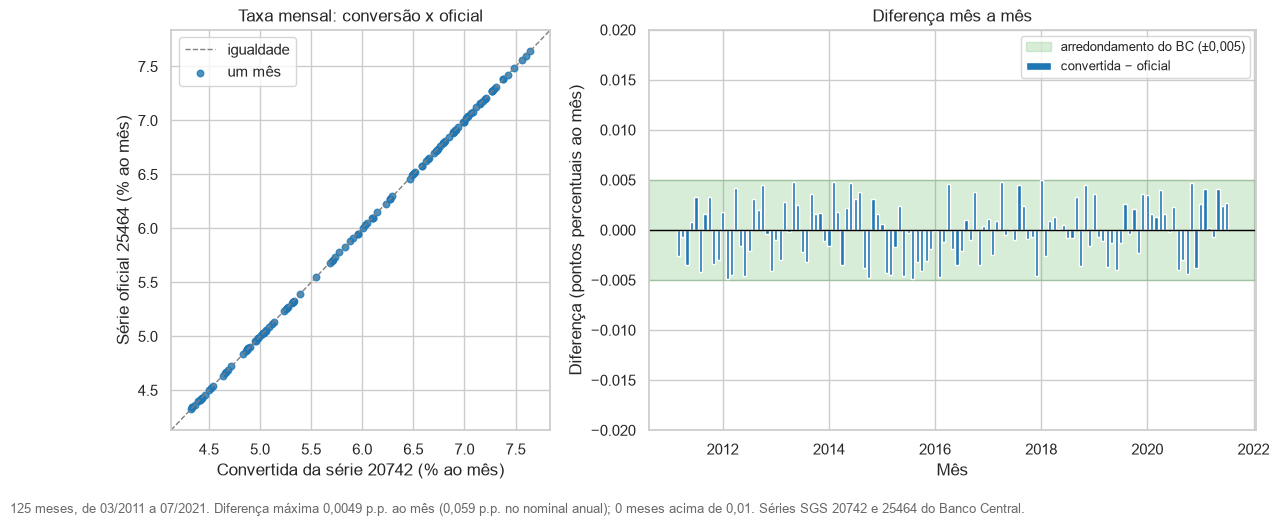

,efetiva_aa,oficial_am,convertida_am,dif_am
count,125.0000,125.0000,125.0000,125.0000
mean,101.2091,5.9465,5.9464,-0.0001
std,23.0338,1.0181,1.0180,0.0030
min,66.3000,4.3300,4.3296,-0.0049
25%,79.8400,5.0100,5.0124,-0.0026
50%,101.9400,6.0300,6.0316,-0.0003
75%,122.4400,6.8900,6.8893,0.0024
max,141.8600,7.6400,7.6375,0.0049


In [15]:
from src.dados.validar_conversao_bc import NOMES_MENSAL, comparar, ler_serie, resumo

arq_mensal = next((RAIZ / 'data' / 'raw' / n for n in NOMES_MENSAL if (RAIZ / 'data' / 'raw' / n).exists()), None)
if arq_mensal is None:
    print('data/raw/bcdata.sgs.25464.csv não encontrado (série mensal oficial do BC, em dadosabertos.bcb.gov.br). Baixe e rode de novo.')
else:
    bc = tabelas['bc_credito_pessoal_mensal']
    efetiva = pd.Series(bc['taxa_aa'].values, index=pd.to_datetime(bc['mes']))
    comp = comparar(efetiva, ler_serie(arq_mensal))
    comp = comp.loc['2011-03-01':'2021-07-01']          # a janela do projeto (concessões do Bondora)
    r = resumo(comp)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1, 1.6]})
    lim = (comp[['convertida_am', 'oficial_am']].min().min() - 0.2, comp[['convertida_am', 'oficial_am']].max().max() + 0.2)
    ax1.plot(lim, lim, color='gray', ls='--', lw=1, label='igualdade')
    ax1.scatter(comp['convertida_am'], comp['oficial_am'], s=22, color='#1f77b4', alpha=0.8, label='um mês')
    ax1.set(xlim=lim, ylim=lim, xlabel='Convertida da série 20742 (% ao mês)', ylabel='Série oficial 25464 (% ao mês)',
            title='Taxa mensal: conversão x oficial')
    ax1.legend(frameon=True, loc='upper left')

    ax2.axhspan(-0.005, 0.005, color='#2ca02c', alpha=0.18, label='arredondamento do BC (±0,005)')
    ax2.bar(comp.index, comp['dif_am'], width=22, color='#1f77b4', label='convertida − oficial')
    ax2.axhline(0, color='black', lw=1)
    ax2.set_ylim(-0.02, 0.02)
    ax2.set(xlabel='Mês', ylabel='Diferença (pontos percentuais ao mês)', title='Diferença mês a mês')
    ax2.legend(frameon=True, loc='upper right', fontsize=9)
    rodape(fig, f"{r['meses']} meses, de {comp.index.min():%m/%Y} a {comp.index.max():%m/%Y}. Diferença máxima {br(r['dif_max_am'], 4)} p.p. ao mês "
                f"({br(r['dif_max_nominal'], 3)} p.p. no nominal anual); {r['acima_da_tolerancia']} meses acima de 0,01. "
                'Séries SGS 20742 e 25464 do Banco Central.', y=-0.03)
    salvar(fig, '10_validacao_conversao_bc')
    plt.show()
    display(comp[['efetiva_aa', 'oficial_am', 'convertida_am', 'dif_am']].describe().round(4))

## Leituras

*(com os dados de 08/11/2026; reescreva se o banco for recarregado)*

1. **Inadimplência:** na Estônia sobe de 21% (2012) para 52% (2016). Espanha e Finlândia entram em 2013 com 72% e 57% e chegam a 79% e 73% em 2016. No conjunto, 56%.
2. **Juro por época:** até 2014 o juro mediano é quase igual em todos os ratings (28% a 31%); a partir de 2015 passa a acompanhar o rating (por exemplo, AA 10% a HR 64% em 2016).
   Na Espanha, o juro mediano sobe de 24% (2013) para 109% (2017). Auditar preço entre épocas exige olhar a época.
3. **Renda:** a Finlândia tem a maior (cerca de 2.000 por mês), depois a Espanha (cerca de 1.300) e a Estônia (de 700 a 1.100, já com 2009–2010 em euros).
4. **Juro e default:** na Estônia, o default cresce com o grupo de juro (31% no Q1 e 58% no Q5). Na Espanha e na Finlândia, o juro cobrado varia bastante e o default varia pouco (73% a 87% e 68% a 78%).
5. **Gênero:** a proporção de mulheres na Estônia vai de 45% (2016) para 9% (2018) e volta a 51% (2020): indício de erro de codificação, e por isso a equidade de gênero usa 2013–2016.
6. **Moeda:** a renda e os passivos da Estônia até 2010 estavam em coroas. A renda mediana ia de 12.000 (dez/2010) para 860 (jan/2011) e, depois da correção (÷ 15,6466), de cerca de 770 para 860. 1.822 contratos, 9% do treino.
7. **Retorno realizado:** a base de modelagem (73,0 mi € concedidos, 2009–2016) devolveu, em soma, praticamente o que emprestou (resultado de −0,01 mi €). Por país: Estônia +6,05 mi € (+15%), Espanha −3,89 mi € (−31%) e Finlândia −2,17 mi € (−11%).
   Por safra o retorno cai de +28% (2013) para +10% (2014), −5% (2015) e −13% (2016). Os reestruturados somam +1,34 mi € (+5,6%) e os demais −1,35 mi € (−2,7%).
8. **Conversão do BC:** a taxa efetiva da série 20742, convertida para mensal, difere da série mensal oficial (25464) em no máximo 0,005 ponto percentual ao mês nos 125 meses da janela do projeto, que é o arredondamento do próprio BC. Ou seja, a conversão para nominal está validada contra a série oficial.
9. **Equidade e carteira auditada:** as figuras 8 e 9 dependem dos arquivos do Samuel; quando eles chegarem, acrescente aqui o que mostram.